<a href="https://colab.research.google.com/github/Danish-Hadif/data-science-toolkit/blob/main/Tutorials/Social_Media_Effect.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/social_media_students_500.csv')

In [ ]:
df

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024006,20,Male,Undergraduate,TikTok,5.6,1.8,Smartphone,8.3,3,False,Sometimes,10.0,88,3.72,Beneficial
1,STU_2024020,17,Male,High School,Instagram,3.5,1.1,Smartphone,7.9,3,False,Frequently,2.0,94,3.75,Beneficial
2,STU_2024021,16,Female,High School,Instagram,2.4,2.5,Smartphone,7.4,3,True,Always,1.0,98,4.00,Beneficial
3,STU_2024022,23,Male,Postgraduate,YouTube,7.4,1.3,Laptop/PC,6.3,2,True,Sometimes,10.0,68,2.82,Beneficial
4,STU_2024031,20,Male,Undergraduate,X (Twitter),8.3,1.8,Smartphone,5.6,1,True,Rarely,22.0,64,3.35,Neutral
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,STU_2028445,17,Male,High School,Instagram,4.6,2.3,Smartphone,5.1,1,False,Frequently,17.0,81,3.18,Beneficial
496,STU_2028447,22,Female,Undergraduate,YouTube,3.6,2.2,Smartphone,8.7,4,True,Frequently,14.0,82,3.47,Beneficial
497,STU_2028483,17,Female,High School,TikTok,5.3,2.2,Smartphone,6.5,3,True,Frequently,13.0,82,3.02,Beneficial
498,STU_2028495,16,Male,High School,YouTube,5.8,1.2,Smartphone,7.8,3,True,Sometimes,11.0,79,2.85,Beneficial


In [ ]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024006,20,Male,Undergraduate,TikTok,5.6,1.8,Smartphone,8.3,3,False,Sometimes,10.0,88,3.72,Beneficial
1,STU_2024020,17,Male,High School,Instagram,3.5,1.1,Smartphone,7.9,3,False,Frequently,2.0,94,3.75,Beneficial
2,STU_2024021,16,Female,High School,Instagram,2.4,2.5,Smartphone,7.4,3,True,Always,1.0,98,4.00,Beneficial
3,STU_2024022,23,Male,Postgraduate,YouTube,7.4,1.3,Laptop/PC,6.3,2,True,Sometimes,10.0,68,2.82,Beneficial
4,STU_2024031,20,Male,Undergraduate,X (Twitter),8.3,1.8,Smartphone,5.6,1,True,Rarely,22.0,64,3.35,Neutral


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   500 non-null    object 
 1   Age                          500 non-null    int64  
 2   Gender                       500 non-null    object 
 3   Academic_Level               500 non-null    object 
 4   Primary_Platform             500 non-null    object 
 5   Daily_Usage_Hours            500 non-null    float64
 6   Weekend_Extra_Hours          500 non-null    float64
 7   Device_Type                  500 non-null    object 
 8   Sleep_Duration_Hours         500 non-null    float64
 9   Sleep_Quality_Score          500 non-null    int64  
 10  Late_Night_Usage             500 non-null    bool   
 11  Social_Comparison_Frequency  500 non-null    object 
 12  Perceived_Stress_Score       485 non-null    float64
 13  Mental_Health_Index 

In [ ]:
df.describe().round(2)

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,500.00,500.00,500.00,500.00,500.00,485.00,500.00,475.00
mean,18.53,5.44,1.78,6.61,2.42,13.69,79.21,3.39
std,1.88,2.72,0.74,1.20,1.04,6.79,12.93,0.40
min,15.00,1.30,0.00,3.00,1.00,0.00,39.00,1.90
25%,17.00,3.40,1.27,5.80,2.00,9.00,71.00,3.14
50%,18.00,4.80,1.80,6.70,2.00,13.00,81.00,3.43
75%,20.00,6.82,2.30,7.50,3.00,18.00,89.00,3.68
max,26.00,14.00,3.90,9.30,5.00,36.00,98.00,4.00


In [ ]:
for col in ["Gender", "Academic_Level", "Primary_Platform", "Overall_Impact"]:
    print(df[col].value_counts(), "\n")


Gender
Female               238
Male                 233
Non-Binary            22
Prefer not to say      7
Name: count, dtype: int64 

Academic_Level
Undergraduate    302
High School      181
Postgraduate      17
Name: count, dtype: int64 

Primary_Platform
Instagram      154
TikTok         139
YouTube        102
Snapchat        44
Reddit          31
X (Twitter)     23
LinkedIn         7
Name: count, dtype: int64 

Overall_Impact
Beneficial    398
Neutral        86
Negative       16
Name: count, dtype: int64 



In [ ]:
missing = df.isna().sum()
print(missing[missing > 0])

print()
print("As a % of all students:")
print((missing[missing > 0] / len(df) * 100).round(1))

Perceived_Stress_Score      15
Academic_Performance_GPA    25
dtype: int64

As a % of all students:
Perceived_Stress_Score      3.0
Academic_Performance_GPA    5.0
dtype: float64


In [ ]:
cols = ["Student_ID", "Daily_Usage_Hours", "Perceived_Stress_Score", "Academic_Performance_GPA"]
df[df["Academic_Performance_GPA"].isna()][cols].head()

,Student_ID,Daily_Usage_Hours,Perceived_Stress_Score,Academic_Performance_GPA
5,STU_2024039,3.3,15.0,NaN
7,STU_2024044,7.6,25.0,NaN
80,STU_2024701,2.0,6.0,NaN
113,STU_2024983,4.8,11.0,NaN
118,STU_2025001,4.0,9.0,NaN


In [ ]:
print("Students before:", len(df))
print("dropna() on everything:   ", len(df.dropna()), "left")
print("dropna on GPA column only:", len(df.dropna(subset=["Academic_Performance_GPA"])), "left")



Students before: 500
dropna() on everything:    460 left
dropna on GPA column only: 475 left


In [ ]:
median_stress = df["Perceived_Stress_Score"].median()
print("Median stress score:", median_stress)

filled = df["Perceived_Stress_Score"].fillna(median_stress)
print("Missing after fill:", filled.isna().sum())

print()
print("Mean before:", round(df["Perceived_Stress_Score"].mean(), 2), "| after:", round(filled.mean(), 2))
print("Spread (std) before:", round(df["Perceived_Stress_Score"].std(), 2), "| after:", round(filled.std(), 2))


Median stress score: 13.0
Missing after fill: 0

Mean before: 13.69 | after: 13.67
Spread (std) before: 6.79 | after: 6.69


In [ ]:
clean = df.copy()      # always clean a COPY, so the original stays safe

clean["Perceived_Stress_Score"] = clean["Perceived_Stress_Score"].fillna(clean["Perceived_Stress_Score"].median())
clean = clean.dropna(subset=["Academic_Performance_GPA"])

print("Students:", len(df), "->", len(clean))
print("Missing values left:", clean.isna().sum().sum())

Students: 500 -> 475
Missing values left: 0


In [ ]:
print("Duplicate rows:      ", clean.duplicated().sum())
print("Duplicate student IDs:", clean["Student_ID"].duplicated().sum())

print()
print("GPA range:  ", clean["Academic_Performance_GPA"].min(), "to", clean["Academic_Performance_GPA"].max(), "(should be 0-4)")
print("Age range:  ", clean["Age"].min(), "to", clean["Age"].max())
print("Sleep range:", clean["Sleep_Duration_Hours"].min(), "to", clean["Sleep_Duration_Hours"].max(), "hours")
print("Usage over 24h a day:", (clean["Daily_Usage_Hours"] > 24).sum(), "students (impossible if > 0)")

Duplicate rows:       0
Duplicate student IDs: 0

GPA range:   1.9 to 4.0 (should be 0-4)
Age range:   15 to 26
Sleep range: 3.0 to 9.3 hours
Usage over 24h a day: 0 students (impossible if > 0)


Normal range: 0.0 to 12.2 hours/day
Students outside it: 18


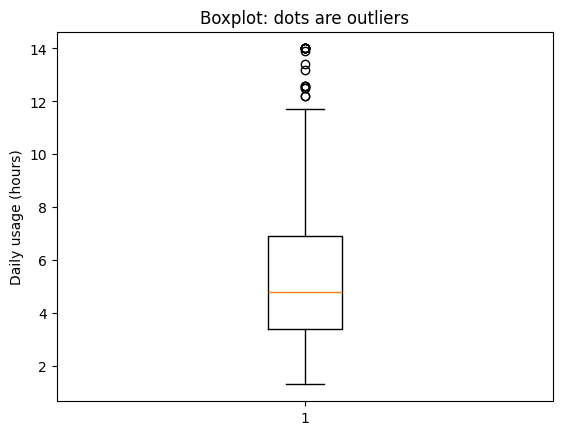

In [ ]:
usage = clean["Daily_Usage_Hours"]
q1, q3 = usage.quantile(0.25), usage.quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print(f"Normal range: {max(low, 0):.1f} to {high:.1f} hours/day")
print("Students outside it:", ((usage < low) | (usage > high)).sum())

plt.boxplot(usage)
plt.ylabel("Daily usage (hours)")
plt.title("Boxplot: dots are outliers")
plt.show()

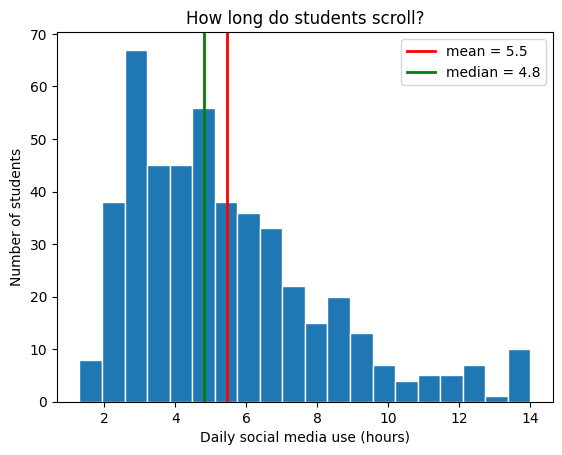

In [ ]:
usage = clean["Daily_Usage_Hours"]

plt.hist(usage, bins=20, edgecolor="white")
plt.axvline(usage.mean(), color="red", linewidth=2, label=f"mean = {usage.mean():.1f}")
plt.axvline(usage.median(), color="green", linewidth=2, label=f"median = {usage.median():.1f}")

plt.xlabel("Daily social media use (hours)")
plt.ylabel("Number of students")
plt.title("How long do students scroll?")
plt.legend()
plt.show()


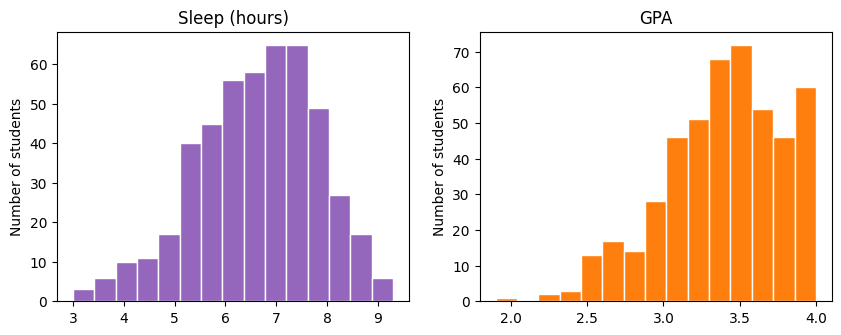

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].hist(clean["Sleep_Duration_Hours"], bins=15, edgecolor="white", color="tab:purple")
axes[0].set_title("Sleep (hours)")

axes[1].hist(clean["Academic_Performance_GPA"], bins=15, edgecolor="white", color="tab:orange")
axes[1].set_title("GPA")

for ax in axes:
    ax.set_ylabel("Number of students")
plt.show()

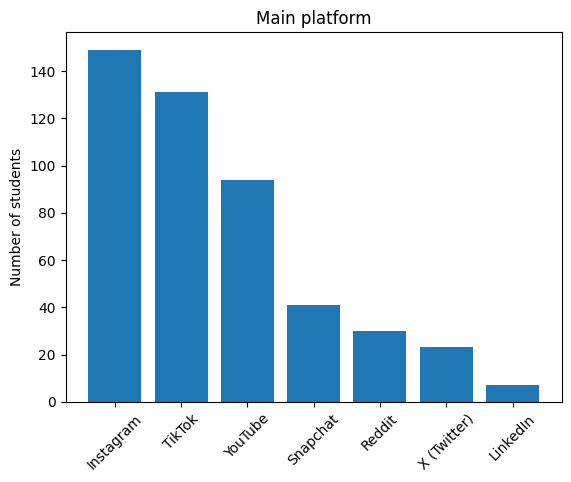

In [ ]:
counts = clean["Primary_Platform"].value_counts()

plt.bar(counts.index, counts.values)
plt.xticks(rotation=45)
plt.ylabel("Number of students")
plt.title("Main platform")
plt.show()

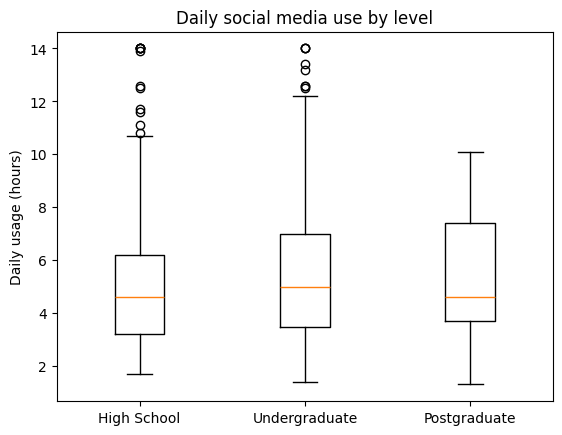

In [ ]:
levels = ["High School", "Undergraduate", "Postgraduate"]
groups = [clean[clean["Academic_Level"] == lv]["Daily_Usage_Hours"] for lv in levels]

plt.boxplot(groups)
plt.xticks([1, 2, 3], levels)
plt.ylabel("Daily usage (hours)")
plt.title("Daily social media use by level")
plt.show()

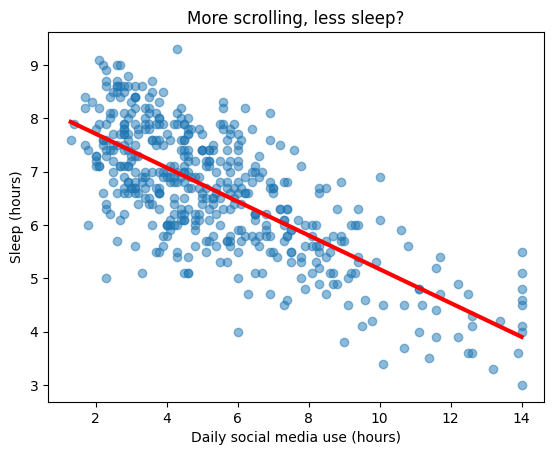

r = -0.73
Each extra hour online goes with -0.32 hours of sleep


In [ ]:
x = clean["Daily_Usage_Hours"]
y = clean["Sleep_Duration_Hours"]

plt.scatter(x, y, alpha=0.5)
slope, intercept = np.polyfit(x, y, 1)
line_x = np.array([x.min(), x.max()])
plt.plot(line_x, slope * line_x + intercept, color="red", linewidth=3)

plt.xlabel("Daily social media use (hours)")
plt.ylabel("Sleep (hours)")
plt.title("More scrolling, less sleep?")
plt.show()

print("r =", round(x.corr(y), 2))
print("Each extra hour online goes with", round(slope, 2), "hours of sleep")

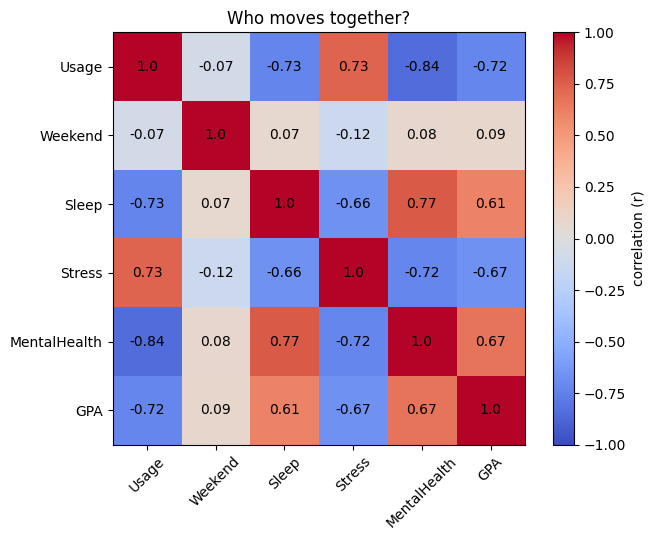

In [ ]:
cols = ["Daily_Usage_Hours", "Weekend_Extra_Hours", "Sleep_Duration_Hours",
        "Perceived_Stress_Score", "Mental_Health_Index", "Academic_Performance_GPA"]
labels = ["Usage", "Weekend", "Sleep", "Stress", "MentalHealth", "GPA"]
corr = clean[cols].corr()

plt.figure(figsize=(7, 5.5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation (r)")
plt.xticks(range(len(cols)), labels, rotation=45)
plt.yticks(range(len(cols)), labels)
for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center")
plt.title("Who moves together?")
plt.tight_layout()
plt.show()

                   students  avg GPA
Daily_Usage_Hours                   
0-3h                     94     3.72
3-6h                    227     3.50
6-9h                    104     3.12
9h+                      50     2.85


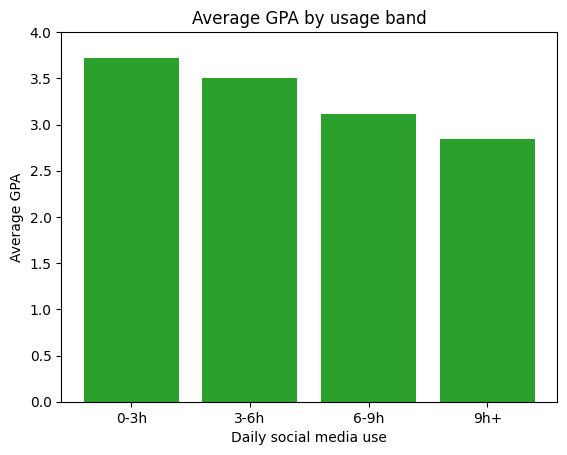

In [ ]:
bands = pd.cut(clean["Daily_Usage_Hours"],
               bins=[0, 3, 6, 9, 24],
               labels=["0-3h", "3-6h", "6-9h", "9h+"])

avg_gpa = clean.groupby(bands, observed=True)["Academic_Performance_GPA"].mean()
n = clean.groupby(bands, observed=True).size()
print(pd.DataFrame({"students": n, "avg GPA": avg_gpa.round(2)}))

plt.bar(avg_gpa.index.astype(str), avg_gpa.values, color="tab:green")
plt.ylim(0, 4)      # start at 0 so the bars are not misleading
plt.xlabel("Daily social media use")
plt.ylabel("Average GPA")
plt.title("Average GPA by usage band")
plt.show()

In [ ]:
clean.groupby("Overall_Impact")[["Daily_Usage_Hours", "Sleep_Duration_Hours",
                                  "Perceived_Stress_Score", "Academic_Performance_GPA"]].mean().round(2)



,Daily_Usage_Hours,Sleep_Duration_Hours,Perceived_Stress_Score,Academic_Performance_GPA
Overall_Impact,,,,
Beneficial,4.45,6.99,11.32,3.51
Negative,12.87,3.97,30.00,2.58
Neutral,8.68,5.39,21.57,2.97


In [ ]:
for col, name in [("Sleep_Duration_Hours", "sleep"),
                  ("Perceived_Stress_Score", "stress"),
                  ("Academic_Performance_GPA", "GPA")]:
    r = clean["Daily_Usage_Hours"].corr(clean[col])
    print(f"Daily use vs {name:6}: r = {r:+.2f}")

Daily use vs sleep : r = -0.73
Daily use vs stress: r = +0.73
Daily use vs GPA   : r = -0.72


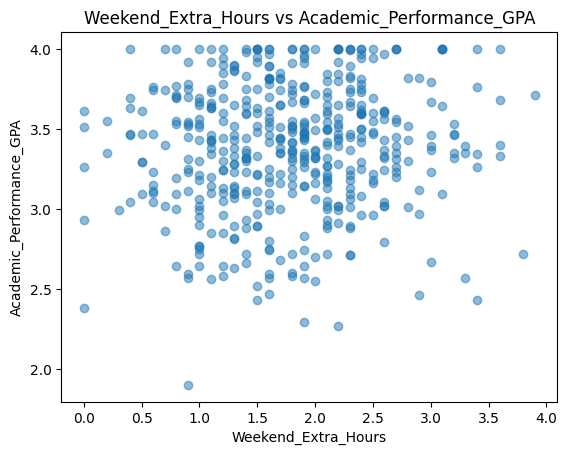

r = 0.09


In [ ]:
x_col = "Weekend_Extra_Hours"   # <-- change me!
y_col = "Academic_Performance_GPA"   # <-- change me!

plt.scatter(clean[x_col], clean[y_col], alpha=0.5)
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title(f"{x_col} vs {y_col}")
plt.show()

print("r =", round(clean[x_col].corr(clean[y_col]), 2))